In [ ]:
Q1)

In [1]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    print("Converted value:", kc)
    print("Converted value type:", type(kc))

    if not math.isfinite(kc):
        print("Invalid input: Kc must be a finite number.")
    elif kc <= 0:
        print("Invalid input: Kc must be greater than 0.")
    else:
        # Kc*x^2 - (3*Kc + 1)*x + 2*Kc = 0
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc

        discriminant = b**2 - 4 * a * c
        print(f"a = {a:.3f}, b = {b:.3f}, c = {c:.3f}")
        print(f"Discriminant = {discriminant:.6f}")

        if discriminant < 0:
            print("There are no real roots.")
        else:
            sqrt_discriminant = math.sqrt(discriminant)
            root1 = (-b + sqrt_discriminant) / (2 * a)
            root2 = (-b - sqrt_discriminant) / (2 * a)
            print(f"Roots: {root1:.6f}, {root2:.6f}")

            physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]

            if not physical_roots:
                print("No root is physically meaningful (0 <= x <= 1).")
            else:
                x = physical_roots[0]
                initial_A = 2.0
                initial_B = 1.0

                equilibrium_A = initial_A - x
                equilibrium_B = initial_B - x
                equilibrium_C = x
                conversion = x / initial_B * 100

                print(f"Physical root x = {x:.6f}")
                print(f"Equilibrium [A] = {equilibrium_A:.3f} mol/L")
                print(f"Equilibrium [B] = {equilibrium_B:.3f} mol/L")
                print(f"Equilibrium [C] = {equilibrium_C:.3f} mol/L")
                print(f"B conversion = {conversion:.3f}%")

                if conversion >= 70:
                    print("Conversion classification: High")
                elif conversion >= 40:
                    print("Conversion classification: Moderate")
                else:
                    print("Conversion classification: Low")

Raw input type: <class 'str'>
Invalid input: Kc must be a number.


Q2)Part A . Hydrogen peroxide decomposes in a batch  reactor by a first order reaction , dC/dt =-kC.Use the euler method :C_new = C_old-K.C_old.t . take C=1.5 mol/L, k=0.05/ min, T=2 min.    (i) using a loop , simulates  20 min  and print a table of time (min),concentration(mol/L) and conversion (%). (ii) using math.exp(), calculate the exact value Ce^(-Kt) at 20min and print the absolute error of the eulers result.(iii) using a while loop,repeat the simulation until it reaches 50% or the time reaches 100 min . print the time needed and the final concentration.                                                                                             part B. Reactor tags such as REACTOR - 07/B-2026 are stored  as text. Write a programm that reads a tag , loops through each character and prints the numberof digits and the sum of the digits . Show a message for an empty tag and for a tag with no digits .Test with REACTOR-07/B-2026, an empty tag and ABCDEF.

In [2]:
# Part A: Euler simulation with a 2-minute time step
initial_concentration = 1.5
rate_constant = 0.05
time_step = 2.0
simulation_time = 20.0

euler_concentration = initial_concentration
print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{0:>4.1f}\t\t{euler_concentration:.6f}\t\t\t{0.0:.2f}")

for step in range(1, int(simulation_time / time_step) + 1):
    euler_concentration -= rate_constant * euler_concentration * time_step
    current_time = step * time_step
    conversion_percent = (
        (initial_concentration - euler_concentration) / initial_concentration * 100
    )
    print(
        f"{current_time:>4.1f}\t\t{euler_concentration:.6f}"
        f"\t\t\t{conversion_percent:.2f}"
    )

exact_concentration = initial_concentration * math.exp(-rate_constant * simulation_time)
absolute_error = abs(euler_concentration - exact_concentration)
print(f"\nExact concentration at {simulation_time:.0f} min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Continue with Euler's method until 50% conversion or 100 minutes
half_concentration = initial_concentration * 0.5
while euler_concentration > half_concentration and current_time < 100:
    euler_concentration -= rate_constant * euler_concentration * time_step
    current_time += time_step

print(f"\nTime to reach 50% conversion (or 100 min): {current_time:.1f} min")
print(f"Final concentration: {euler_concentration:.6f} mol/L")


# Part B: Count and sum the digits in a reactor tag
def analyze_tag(tag):
    if tag == "":
        print("The tag is empty.")
        return

    digits = [character for character in tag if character in "0123456789"]
    if not digits:
        print(f"Tag {tag!r} contains no digits.")
        return

    print(f"Tag: {tag}")
    print(f"Number of digits: {len(digits)}")
    print(f"Sum of digits: {sum(int(digit) for digit in digits)}")


tag_input = input("Enter a reactor tag: ")
analyze_tag(tag_input)

print("\nRequested test cases:")
for sample_tag in ("REACTOR-07/B-2026", "", "ABCDEF"):
    analyze_tag(sample_tag)

Time (min)	Concentration (mol/L)	Conversion (%)
 0.0		1.500000			0.00
 2.0		1.350000			10.00
 4.0		1.215000			19.00
 6.0		1.093500			27.10
 8.0		0.984150			34.39
10.0		0.885735			40.95
12.0		0.797162			46.86
14.0		0.717445			52.17
16.0		0.645701			56.95
18.0		0.581131			61.26
20.0		0.523018			65.13

Exact concentration at 20 min: 0.551819 mol/L
Absolute error: 0.028802 mol/L

Time to reach 50% conversion (or 100 min): 20.0 min
Final concentration: 0.523018 mol/L
Tag: REACTOR-07/B-2026
Number of digits: 6
Sum of digits: 17

Requested test cases:
Tag: REACTOR-07/B-2026
Number of digits: 6
Sum of digits: 17
The tag is empty.
Tag 'ABCDEF' contains no digits.


Q3.Part A. A laboratoryhas n candidate  catalyst and wants to test r of them together(order does not matter). Write a recursive function factorial (n)(remember the base case for 0!) and a function combination (n,r)=n!/(r!(n-r)!) that uses it . Reject invalid input ( negative values,r>n). print the no of possible catalyst sets for n=7,r=2,and show the message for n =4,r=6.                                                                  part B. during a distillation run , samples are taken at times=Fibonacci number * 5 min. Write an iterative function fib_iter(n) thats returns a list of the first n fibonacci numbers,and a recursive function fib_rec(k) that returns the k-th fibonacci number (F0=0,F1=1).For n =9, check that both functions agree and print a  table : sample No.| Fibonacci tag  |  Sampling time (min).

In [3]:
# Part A: Catalyst combinations

def factorial(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or not isinstance(r, int):
        raise ValueError("n and r must be integers.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


print("Number of catalyst sets for n=7, r=2:", combination(7, 2))

try:
    combination(4, 6)
except ValueError as error:
    print("Invalid input for n=4, r=6:", error)


# Part B: Fibonacci sampling schedule

def fib_iter(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    numbers = []
    first, second = 0, 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_rec(k):
    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 9
fibonacci_numbers = fib_iter(n)
recursive_numbers = [fib_rec(index) for index in range(n)]

print("\nIterative and recursive results agree:", fibonacci_numbers == recursive_numbers)
print("\nSample No.\tFibonacci tag\tSampling time (min)")

for sample_number, fibonacci_tag in enumerate(fibonacci_numbers, start=1):
    sampling_time = fibonacci_tag * 5
    print(f"{sample_number}\t\t{fibonacci_tag}\t\t{sampling_time}")

Number of catalyst sets for n=7, r=2: 21
Invalid input for n=4, r=6: r cannot be greater than n.

Iterative and recursive results agree: True

Sample No.	Fibonacci tag	Sampling time (min)
1		0		0
2		1		5
3		1		5
4		2		10
5		3		15
6		5		25
7		8		40
8		13		65
9		21		105


CSV shape: (6, 3)
Data types:
 TIME_min                     int64
RUN1_MOL_L_low_loading     float64
RUN2_MOL_L_high_loading    float64
dtype: object

Run 1 mean: 0.770, standard deviation: 0.284
Run 2 mean: 0.550, standard deviation: 0.392
Run 2 shows more variation (by standard deviation).


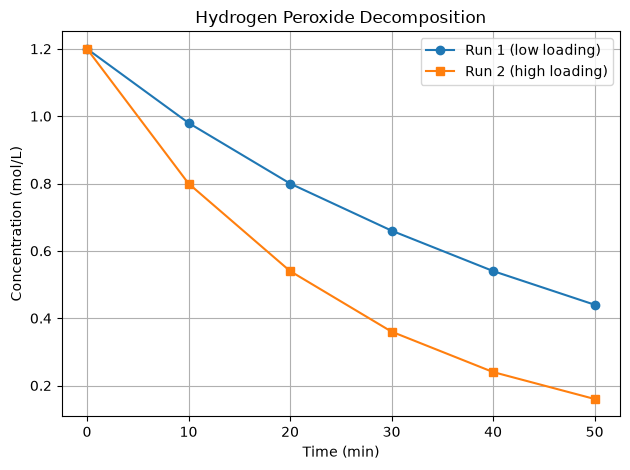


Mean P*V (K): 2.974 bar·L


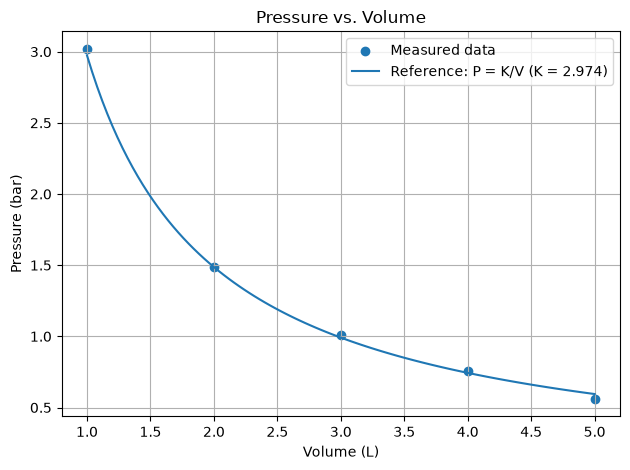

In [7]:
import pandas as pd

import matplotlib.pyplot as plt

# Part A: Create, save, and reload the kinetics data
kinetics_df = pd.DataFrame({
    "TIME_min": [0, 10, 20, 30, 40, 50],
    "RUN1_MOL_L_low_loading": [1.20, 0.98, 0.80, 0.66, 0.54, 0.44],
    "RUN2_MOL_L_high_loading": [1.20, 0.80, 0.54, 0.36, 0.24, 0.16],
})

kinetics_df.to_csv("kinectics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

reloaded_df = pd.read_csv("kinectics.csv")
print("CSV shape:", reloaded_df.shape)
print("Data types:\n", reloaded_df.dtypes)

# Part B: Summary statistics and variation
run1_mean = reloaded_df["RUN1_MOL_L_low_loading"].mean()
run1_std = reloaded_df["RUN1_MOL_L_low_loading"].std()
run2_mean = reloaded_df["RUN2_MOL_L_high_loading"].mean()
run2_std = reloaded_df["RUN2_MOL_L_high_loading"].std()

print(f"\nRun 1 mean: {run1_mean:.3f}, standard deviation: {run1_std:.3f}")
print(f"Run 2 mean: {run2_mean:.3f}, standard deviation: {run2_std:.3f}")

if run1_std > run2_std:
    print("Run 1 shows more variation (by standard deviation).")
elif run2_std > run1_std:
    print("Run 2 shows more variation (by standard deviation).")
else:
    print("Both runs show equal variation (by standard deviation).")

# Part C: Plot both concentration runs
plt.figure()
plt.plot(
    reloaded_df["TIME_min"],
    reloaded_df["RUN1_MOL_L_low_loading"],
    marker="o",
    label="Run 1 (low loading)",
)
plt.plot(
    reloaded_df["TIME_min"],
    reloaded_df["RUN2_MOL_L_high_loading"],
    marker="s",
    label="Run 2 (high loading)",
)
plt.title("Hydrogen Peroxide Decomposition")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part D: Pressure-volume data and reference curve
volume_L = [1, 2, 3, 4, 5]
pressure_bar = [3.02, 1.49, 1.01, 0.76, 0.56]

k_value = sum(v * p for v, p in zip(volume_L, pressure_bar)) / len(volume_L)
curve_volume = [1 + i * 4 / 100 for i in range(101)]
curve_pressure = [k_value / v for v in curve_volume]

print(f"\nMean P*V (K): {k_value:.3f} bar·L")

plt.figure()
plt.scatter(volume_L, pressure_bar, label="Measured data")
plt.plot(curve_volume, curve_pressure, label=f"Reference: P = K/V (K = {k_value:.3f})")
plt.title("Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
